# 15 · Error bars and a fair comparison table

**Goal.** Every number in this project so far is a single point estimate. An external review pointed out that the evaluation is saturated (AUC ≈ 1.0 on most sets), so the differences that matter are small rates (a few false flags out of hundreds of essays) where a point estimate hides a lot of noise. This notebook puts honest error bars on them. No model is trained here.

1. Per-essay scores for every model, computed once and saved (`results/15_scores.csv`), because nothing per-essay was saved before.
2. Why a **Wilson interval** (and not the textbook formula) for a small rate, and a **cluster bootstrap** for AUC and for anything that involves a threshold.
3. How much the **strict (0.5%) and standard (1%) thresholds move** if the validation set had been a different draw, and what range of held-out-prompt false-flag rates that implies.
4. **One comparison table** where every model is scored the same way: threshold chosen on val for 1% false flags, then % AI caught and % humans flagged on each slice, plus the worst single prompt, all with intervals.
5. An audit of the README and model-card claims against those intervals.

Rule kept from the earlier notebooks: every *decision* (thresholds) uses `val` only; the held-out sets are only read to report.

In [1]:
import os
os.environ['HF_HUB_OFFLINE'] = '1'
import sys
sys.path.append('..')

import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from gensim.models import KeyedVectors
from gensim.utils import simple_preprocess
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import roc_auc_score

from src.data import load_splits
from src.detector import Detector
from src.evaluate import (wilson_interval, percent_with_interval, ClusterSampler, auc_with_interval,
                          bootstrap_interval, threshold_for_fpr)

SEED, N_BOOT = 42, 1000
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 80)
HUMAN, AI = '#2a78d6', '#eb6834'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e6e3', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#9a9a94', 'axes.titleweight': 'bold'})

data = load_splits()
train = data[data['split'] == 'train']
ev = data[data['split'].isin(['val', 'test', 'heldout_prompt', 'heldout_generator'])]
print(ev['split'].value_counts().to_string())

split
heldout_prompt       7135
test                 3501
val                  3501
heldout_generator    2721


## 1 · Per-essay scores for every model

Notebooks 04–10 saved **aggregate** numbers (a CSV of rates and AUCs per model), not the score of each essay, so an interval cannot be computed from them. We need the scores themselves. Six models, all on the same scale "higher = more AI-like":

| column | model | how it is scored here |
|---|---|---|
| `roberta` | fine-tuned DistilRoBERTa (08) | `Detector.score`: first 512 tokens, logit |
| `tfidf` | TF-IDF (1–2 grams) + LinearSVM, C=1 | refit on `train` only, exactly as in 09 (about a minute); distance from the hyperplane |
| `bilstm_sg`, `bigru_sg`, `bilstm_rand` | the three recurrent models from 07 | the saved weights, run on the first 384 tokens; logit |
| `gpt2` | zero-shot GPT-2 perplexity (10) | minus the saved log-perplexity (a *less* surprising essay is more AI-like) |

The first run takes a few minutes and writes `results/15_scores.csv`; later runs just read it. Only the four evaluation splits are scored (the training essays are not needed).

In [2]:
class RNNClassifier(nn.Module):
    """The BiLSTM / BiGRU from 07_bilstm.ipynb, unchanged (we only load its saved weights)."""
    def __init__(self, emb_matrix, cell='lstm', hidden=64, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        rnn = nn.LSTM if cell == 'lstm' else nn.GRU
        self.rnn = rnn(emb_matrix.shape[1], hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(2 * hidden, 1)

    def forward(self, x, lengths):
        h, _ = self.rnn(self.drop(self.emb(x)))
        pooled = h.masked_fill((x == 0).unsqueeze(-1), float('-inf')).max(dim=1).values
        return self.out(self.drop(pooled)).squeeze(1)


@torch.no_grad()
def rnn_logits(model, ids, batch_size=256):
    """Logit per essay (07 stored sigmoid probabilities; the logit ranks identically and is what we threshold)."""
    model.eval()
    out = np.empty(len(ids), dtype=np.float32)
    order = np.argsort([len(x) for x in ids], kind='stable')
    for s in range(0, len(order), batch_size):
        chunk = order[s:s + batch_size]
        lengths = torch.tensor([len(ids[i]) for i in chunk])
        x = torch.zeros(len(chunk), int(lengths.max()), dtype=torch.long)
        for r, i in enumerate(chunk):
            x[r, :len(ids[i])] = torch.tensor(ids[i])
        out[chunk] = model(x, lengths).numpy()
    return out


def score_everything(ev, train):
    """One column of per-essay scores (higher = more AI-like) for each model, for the essays in `ev`."""
    out = pd.DataFrame(index=ev.index)
    t0 = time.time()
    det = Detector()                                              # the fine-tuned DistilRoBERTa from 08, first 512 tokens
    out['roberta'] = det.score(ev['text'].tolist())
    del det; torch.cuda.empty_cache()
    print(f"DistilRoBERTa {time.time() - t0:.0f}s")

    t0 = time.time()                                               # TF-IDF + LinearSVM: refit exactly as in 09 (train only)
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=200_000, sublinear_tf=True).fit(train['text'])
    svm = LinearSVC(C=1).fit(vec.transform(train['text']), train['label'])
    out['tfidf'] = svm.decision_function(vec.transform(ev['text']))
    print(f"TF-IDF {time.time() - t0:.0f}s")

    t0 = time.time()                                               # BiLSTM / BiGRU: saved weights from 07
    kv = KeyedVectors.load('../models/w2v_skipgram.kv')
    itos = ['<pad>', '<unk>'] + list(kv.index_to_key)
    stoi = {w: i for i, w in enumerate(itos)}
    ids = [[stoi.get(w, 1) for w in simple_preprocess(t, min_len=1, max_len=30)[:384]] or [1] for t in ev['text']]
    blank = np.zeros((len(itos), kv.vector_size), dtype=np.float32)    # real values come from the saved weights
    for col, cell, file in [('bilstm_sg', 'lstm', 'bilstm_sg'), ('bigru_sg', 'gru', 'bigru_sg'), ('bilstm_rand', 'lstm', 'bilstm_rand')]:
        m = RNNClassifier(blank, cell)
        m.load_state_dict(torch.load(f'../models/{file}.pt'))
        out[col] = rnn_logits(m, ids)
    print(f"BiLSTM/BiGRU {time.time() - t0:.0f}s")

    g = pd.read_csv('../results/10_gpt2_features.csv', index_col='row_id')   # GPT-2 scored every essay in 10
    out['gpt2'] = -g.loc[ev.index, 'log_ppl'].to_numpy()                      # low perplexity = AI-like, so negate
    return out

In [3]:
SCORES = '../results/15_scores.csv'
if os.path.exists(SCORES):
    scores = pd.read_csv(SCORES, index_col='row_id')
    print('loaded', SCORES, scores.shape)
else:
    scores = score_everything(ev, train)
    scores.to_csv(SCORES)
    print('wrote', SCORES, scores.shape)
assert scores.index.equals(ev.index) and not scores.isna().any().any()
scores.describe().round(2)

loaded ../results/15_scores.csv (16858, 6)


,roberta,tfidf,bilstm_sg,bigru_sg,bilstm_rand,gpt2
count,16858.00,16858.00,16858.00,16858.00,16858.00,16858.00
mean,0.15,-0.11,-0.32,-0.28,-1.15,-2.92
std,9.11,1.05,6.07,5.94,5.97,0.71
min,-9.47,-2.43,-7.69,-8.79,-8.53,-5.56
25%,-9.03,-1.00,-6.23,-6.18,-7.33,-3.42
50%,-5.57,-0.31,-2.75,-1.77,-1.85,-3.05
75%,9.73,0.80,6.89,6.33,5.64,-2.33
max,9.77,2.71,8.15,8.73,7.48,-0.19


### Sanity check: do these scores reproduce what was saved earlier?

If these fresh scores are right, they must give back the thresholds that `09_threshold.ipynb` saved (the 1% and 0.5% quantiles of validation-human scores), and the test AUCs that 07 and 10 reported. Any mismatch would mean something here is different from the original pipeline.

In [4]:
val_h = ev[(ev['split'] == 'val') & (ev['label'] == 0)]
old = pd.read_csv('../results/09_thresholds.csv', index_col=0)
rows = []
for col, oldcol in [('roberta', 'roberta'), ('tfidf', 'tfidf')]:
    for target in (0.01, 0.005):
        rows.append({'model': col, 'target FPR': target, 'saved in 09': float(old.loc[str(target), oldcol]),
                     'recomputed': threshold_for_fpr(scores.loc[val_h.index, col], target)})
chk = pd.DataFrame(rows)
chk['difference'] = chk['recomputed'] - chk['saved in 09']
print(chk.round(3).to_string(index=False))
assert chk['difference'].abs().max() < 0.05, 'thresholds do not reproduce 09'

test = ev[ev['split'] == 'test']
saved07 = pd.read_csv('../results/07_bilstm.csv', index_col=0).query("subset == 'all'")['test_auc']
saved10 = pd.read_csv('../results/10_zero_shot.csv', index_col=0).query("subset == 'all'").loc['GPT-2 perplexity (zero-shot)', 'test_auc']
for col, name in [('bilstm_sg', 'BiLSTM (Skip-gram init)'), ('bigru_sg', 'BiGRU (Skip-gram init)'), ('bilstm_rand', 'BiLSTM (random init)')]:
    auc = roc_auc_score(test['label'], scores.loc[test.index, col])
    print(f"{col:12s} test AUC {auc:.4f}   (07 saved {saved07[name]:.4f})")
    assert abs(auc - saved07[name]) < 0.001
auc = roc_auc_score(test['label'], scores.loc[test.index, 'gpt2'])
print(f"{'gpt2':12s} test AUC {auc:.4f}   (10 saved {saved10:.4f})")
assert abs(auc - saved10) < 0.001
print('\nAll scores reproduce the earlier notebooks.')

  model  target FPR  saved in 09  recomputed  difference
roberta       0.010        4.666       4.666        -0.0
roberta       0.005        7.796       7.796        -0.0
  tfidf       0.010       -0.508      -0.508         0.0
  tfidf       0.005       -0.388      -0.388         0.0
bilstm_sg    test AUC 0.9991   (07 saved 0.9991)
bigru_sg     test AUC 0.9998   (07 saved 0.9998)
bilstm_rand  test AUC 0.9989   (07 saved 0.9988)
gpt2         test AUC 0.9714   (10 saved 0.9714)

All scores reproduce the earlier notebooks.


## 2 · Why a Wilson interval for small rates

The usual textbook interval for a rate is `p ± 1.96·√(p(1−p)/n)`. It is built around the *observed* rate, so it breaks exactly where this project lives, at rates of 0–5%:

- **0 flagged out of 300** gives `p = 0`, so the formula says "exactly 0%, zero uncertainty". That is absurd: 300 clean essays cannot prove the true rate is 0.
- **2 flagged out of 300** gives a lower end below 0%.
- It is only accurate when there are at least ~10 events, and a rate of 0.5% on 2,000 essays has 10.

The **Wilson interval** instead asks "which true rates would produce this count without being surprising?". It never leaves 0–100%, is not zero-width at 0 events, and is accurate down to a handful of events. Both are shown below for the case that matters (T5 paraphrasing "raised false flags from 2/300 to 8/300").

In [5]:
def normal_interval(k, n):
    p = k / n
    half = 1.96 * np.sqrt(p * (1 - p) / n)
    return p - half, p + half

demo = []
for k, n in [(0, 300), (2, 300), (8, 300), (10, 2000), (23, 4464)]:
    nlo, nhi = normal_interval(k, n)
    wlo, whi = wilson_interval(k, n)
    demo.append({'flagged / n': f'{k} / {n}', 'rate': f'{100 * k / n:.2f}%',
                 'normal approx. (%)': f'[{100 * nlo:.2f}, {100 * nhi:.2f}]',
                 'Wilson (%)': f'[{100 * wlo:.2f}, {100 * whi:.2f}]'})
pd.DataFrame(demo).set_index('flagged / n')

,rate,normal approx. (%),Wilson (%)
flagged / n,,,
0 / 300,0.00%,"[0.00, 0.00]","[0.00, 1.26]"
2 / 300,0.67%,"[-0.25, 1.59]","[0.18, 2.40]"
8 / 300,2.67%,"[0.84, 4.49]","[1.36, 5.17]"
10 / 2000,0.50%,"[0.19, 0.81]","[0.27, 0.92]"
23 / 4464,0.52%,"[0.31, 0.73]","[0.34, 0.77]"


For everything that is *not* a simple count (an AUC, or a rate whose threshold was itself estimated from data), we use a **percentile bootstrap**: redraw the essays with replacement 1,000 times (seed 42), recompute the statistic each time, and take the 2.5th and 97.5th percentiles. Two choices:

- We redraw **whole `dup_cluster` groups**, not single essays, because near-duplicate essays are not independent (`ClusterSampler` in `src/evaluate.py`).
- For a *threshold-based* rate the bootstrap also redraws the **validation humans the threshold was chosen on**, so the interval includes the noise in the threshold, which a Wilson interval on the held-out count alone ignores. (Section 4 reports both.)

## 3 · How much do the thresholds move?

The strict threshold is the 99.5th percentile of validation-human scores. With 2,291 validation humans that is the score that only about 11 essays exceed. A different random draw of validation essays would have put the line somewhere else. We redraw the validation humans 1,000 times, recompute both thresholds each time, and apply each redrawn threshold to the held-out essays.

Two intervals for the held-out false-flag rate:

- **threshold only**: the held-out humans stay fixed; only the threshold moves.
- **threshold + held-out sample**: the held-out humans are redrawn too (the full uncertainty).

In [6]:
model = 'roberta'
val_scores = scores.loc[val_h.index, model].to_numpy()
ho_h = ev[(ev['split'] == 'heldout_prompt') & (ev['label'] == 0)]
test_h = ev[(ev['split'] == 'test') & (ev['label'] == 0)]
sets = {'held-out prompts, on-topic humans': ho_h[ho_h['on_topic']],
        'held-out prompts, all humans': ho_h,
        'Summer projects (on-topic humans)': ho_h[ho_h['on_topic'] & (ho_h['prompt_name'] == 'Summer projects')],
        'Electoral college (on-topic humans)': ho_h[ho_h['on_topic'] & (ho_h['prompt_name'] != 'Summer projects')],
        'test, on-topic humans': test_h[test_h['on_topic']]}
print(ho_h.groupby('prompt_name').size().to_string(), '\n')

rng = np.random.default_rng(SEED)
val_sampler = ClusterSampler(val_h['dup_cluster'])
samplers = {k: ClusterSampler(v['dup_cluster']) for k, v in sets.items()}
arr = {k: scores.loc[v.index, model].to_numpy() for k, v in sets.items()}

rows, boot_thr = [], {}
for target in (0.005, 0.01):
    thr_point = threshold_for_fpr(val_scores, target)
    n_above = int((val_scores >= thr_point).sum())
    thr_draws, fixed, full = [], {k: [] for k in sets}, {k: [] for k in sets}
    for b in range(N_BOOT):
        thr_b = np.quantile(val_scores[val_sampler.draw(rng)], 1 - target)
        thr_draws.append(thr_b)
        for k in sets:
            fixed[k].append((arr[k] >= thr_b).mean())
            full[k].append((arr[k][samplers[k].draw(rng)] >= thr_b).mean())
    boot_thr[target] = np.array(thr_draws)
    lo, hi = np.percentile(thr_draws, [2.5, 97.5])
    rows.append({'target FPR': target, 'set': 'THRESHOLD (logit)', 'point': thr_point, 'only threshold lo': lo, 'only threshold hi': hi,
                 'full lo': np.nan, 'full hi': np.nan, 'k': n_above, 'n': len(val_scores)})
    for k in sets:
        flagged = int((arr[k] >= thr_point).sum())
        wlo, whi = wilson_interval(flagged, len(arr[k]))
        rows.append({'target FPR': target, 'set': k, 'point': 100 * flagged / len(arr[k]),
                     'only threshold lo': 100 * np.percentile(fixed[k], 2.5), 'only threshold hi': 100 * np.percentile(fixed[k], 97.5),
                     'full lo': 100 * np.percentile(full[k], 2.5), 'full hi': 100 * np.percentile(full[k], 97.5),
                     'wilson lo': 100 * wlo, 'wilson hi': 100 * whi, 'k': flagged, 'n': len(arr[k])})
thr_table = pd.DataFrame(rows)
thr_table.round(2)

prompt_name
Does the electoral college work?    2714
Summer projects                     1750 



,target FPR,set,point,only threshold lo,only threshold hi,full lo,full hi,k,n,wilson lo,wilson hi
0,0.00,THRESHOLD (logit),7.80,5.43,9.05,NaN,NaN,12,2291,NaN,NaN
1,0.00,"held-out prompts, on-topic humans",2.31,0.93,3.67,0.86,3.64,102,4420,1.90,2.79
2,0.00,"held-out prompts, all humans",2.28,0.92,3.63,0.84,3.63,102,4464,1.89,2.77
3,0.00,Summer projects (on-topic humans),5.15,2.06,7.50,1.89,7.56,90,1746,4.21,6.29
4,0.00,Electoral college (on-topic humans),0.45,0.19,1.16,0.11,1.26,12,2674,0.26,0.78
5,0.00,"test, on-topic humans",0.40,0.18,0.71,0.09,0.87,9,2272,0.21,0.75
6,0.01,THRESHOLD (logit),4.67,2.20,7.48,NaN,NaN,23,2291,NaN,NaN
7,0.01,"held-out prompts, on-topic humans",3.85,2.56,4.71,2.44,4.92,170,4420,3.32,4.45
8,0.01,"held-out prompts, all humans",3.81,2.53,4.68,2.35,4.88,170,4464,3.29,4.41
9,0.01,Summer projects (on-topic humans),7.73,5.61,9.28,5.21,9.74,135,1746,6.57,9.08


Validation humans above the threshold:
  target 0.5%: threshold 7.80 (95% range 5.43 to 9.05), 12 of 2291 validation humans are at or above it
  target 1.0%: threshold 4.67 (95% range 2.20 to 7.48), 23 of 2291 validation humans are at or above it


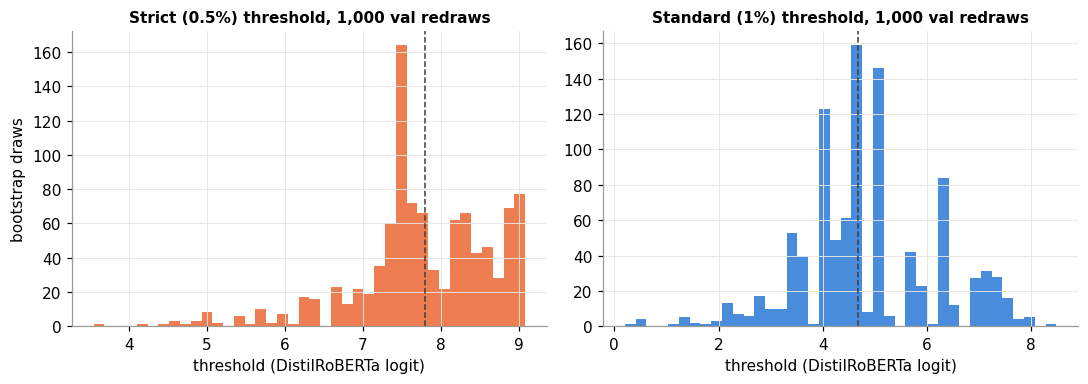

In [7]:
print("Validation humans above the threshold:")
for target in (0.005, 0.01):
    r = thr_table[(thr_table['target FPR'] == target) & (thr_table['set'] == 'THRESHOLD (logit)')].iloc[0]
    print(f"  target {target:.1%}: threshold {r['point']:.2f} (95% range {r['only threshold lo']:.2f} to {r['only threshold hi']:.2f}), "
          f"{int(r['k'])} of {int(r['n'])} validation humans are at or above it")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, target, color in zip(axes, (0.005, 0.01), (AI, HUMAN)):
    d = boot_thr[target]
    ax.hist(d, bins=40, color=color, alpha=0.85)
    ax.axvline(threshold_for_fpr(val_scores, target), color='#3d3d3a', linestyle='--', linewidth=1)
    ax.set_title(f"{'Strict (0.5%)' if target == 0.005 else 'Standard (1%)'} threshold, 1,000 val redraws", fontsize=10)
    ax.set_xlabel('threshold (DistilRoBERTa logit)')
axes[0].set_ylabel('bootstrap draws')
fig.tight_layout()
fig.savefig('../images/15_threshold_bootstrap.png', dpi=150, bbox_inches='tight')
plt.show()
thr_table.round(4).to_csv('../results/15_threshold_bootstrap.csv', index=False)

## 4 · One comparison table for every model

Every model gets the same treatment so the table can be compared across rows:

1. **Threshold:** the score where 1% of `val` humans are flagged (as in 09; chosen on val only).
2. **Apply it** to the held-out slices and report **% humans flagged** (test, held-out prompts, the worst single held-out prompt, the worst single test prompt) and **% AI caught** (test, held-out prompts, held-out generators).
3. **Two intervals** per number: *Wilson* (the held-out essays redrawn, threshold fixed) and a **full-pipeline bootstrap** (validation humans redrawn too, so the threshold noise is inside the interval). The tables below print the full-pipeline one, because it is the honest one; both are in `results/15_comparison.csv`.
4. Reported twice, as everywhere in this project: **all essays**, and **on-topic only** (06), which is the headline.

"Worst single prompt" is the prompt with the highest false-flag rate. Picking the worst of several noisy rates biases it upwards, so the bootstrap redraws the maximum itself, not just that prompt (a fair interval for "the worst prompt, whichever it is").

In [8]:
MODELS = {'DistilRoBERTa (fine-tuned)': 'roberta', 'TF-IDF + LinearSVM': 'tfidf', 'BiGRU (Skip-gram init)': 'bigru_sg',
          'BiLSTM (Skip-gram init)': 'bilstm_sg', 'BiLSTM (random init)': 'bilstm_rand', 'GPT-2 perplexity (zero-shot)': 'gpt2'}
TARGET = 0.01
val_arr = {m: scores.loc[val_h.index, c].to_numpy() for m, c in MODELS.items()}
thr0 = {m: threshold_for_fpr(val_arr[m], TARGET) for m in MODELS}
print({m: round(t, 3) for m, t in thr0.items()})

def make_stats(d):
    """The things to report for one subset d of the evaluation essays: {name: (parts, how to combine the parts)}."""
    S = lambda df: dict(df=df, scores={m: scores.loc[df.index, c].to_numpy() for m, c in MODELS.items()}, sampler=ClusterSampler(df['dup_cluster']))
    h, a = d[d['label'] == 0], d[d['label'] == 1]
    sp = lambda df, s: df[df['split'] == s]
    stats = {
        'humans flagged: test': ([S(sp(h, 'test'))], 'one'),
        'humans flagged: held-out prompts': ([S(sp(h, 'heldout_prompt'))], 'one'),
        'humans flagged: worst held-out prompt': ([S(g) for _, g in sp(h, 'heldout_prompt').groupby('prompt_name')], 'max'),
        'humans flagged: worst test prompt': ([S(g) for _, g in sp(h, 'test').groupby('prompt_name')], 'max'),
        'AI caught: test': ([S(sp(a, 'test'))], 'one'),
        'AI caught: held-out prompts': ([S(sp(a, 'heldout_prompt'))], 'one'),
        'AI caught: held-out generators': ([S(sp(a, 'heldout_generator'))], 'one')}
    return stats

def run_comparison(d, label):
    stats = make_stats(d)
    # point estimates + Wilson
    out = {}
    for name, (parts, how) in stats.items():
        for m in MODELS:
            ks = [(int((p['scores'][m] >= thr0[m]).sum()), len(p['df'])) for p in parts]
            rates = [k / n for k, n in ks]
            j = int(np.argmax(rates))
            k, n = ks[j]
            detail = parts[j]['df']['prompt_name'].iloc[0] if how == 'max' else ''
            wlo, whi = wilson_interval(k, n)
            out[(name, m)] = dict(subset=label, metric=name, model=m, k=k, n=n, detail=detail, point=100 * k / n, wilson_lo=100 * wlo, wilson_hi=100 * whi)
    # full-pipeline bootstrap: redraw the validation humans (threshold) and every evaluation part, same draws for all models
    rng = np.random.default_rng(SEED)
    draws = {key: [] for key in out}
    for b in range(N_BOOT):
        vr = val_sampler.draw(rng)
        thr_b = {m: np.quantile(val_arr[m][vr], 1 - TARGET) for m in MODELS}
        for name, (parts, how) in stats.items():
            per_part = [(p['sampler'].draw(rng), p) for p in parts]
            for m in MODELS:
                rates = [(p['scores'][m][rows] >= thr_b[m]).mean() for rows, p in per_part]
                draws[(name, m)].append(max(rates) if how == 'max' else rates[0])
    for key, row in out.items():
        row['boot_lo'], row['boot_hi'] = 100 * np.percentile(draws[key], [2.5, 97.5])
    return pd.DataFrame(out.values())

t0 = time.time()
comparison = pd.concat([run_comparison(ev, 'all essays'), run_comparison(ev[ev['on_topic']], 'on-topic only')], ignore_index=True)
print(f'{len(comparison)} rows, {time.time() - t0:.0f}s')
comparison.round(3).to_csv('../results/15_comparison.csv', index=False)

def show(subset):
    d = comparison[comparison['subset'] == subset].copy()
    d['cell'] = d.apply(lambda r: f"{r['point']:.2f} [{r['boot_lo']:.1f}, {r['boot_hi']:.1f}]", axis=1)
    t = d.pivot(index='model', columns='metric', values='cell').loc[list(MODELS)]
    order = ['humans flagged: test', 'humans flagged: held-out prompts', 'humans flagged: worst held-out prompt', 'humans flagged: worst test prompt',
             'AI caught: test', 'AI caught: held-out prompts', 'AI caught: held-out generators']
    return t[order]

print('ALL ESSAYS: % with full-pipeline 95% interval, threshold = 1% of val humans'); show('all essays')

{'DistilRoBERTa (fine-tuned)': 4.666, 'TF-IDF + LinearSVM': -0.508, 'BiGRU (Skip-gram init)': -0.504, 'BiLSTM (Skip-gram init)': -0.995, 'BiLSTM (random init)': -0.599, 'GPT-2 perplexity (zero-shot)': -2.395}


84 rows, 15s
ALL ESSAYS: % with full-pipeline 95% interval, threshold = 1% of val humans


metric,humans flagged: test,humans flagged: held-out prompts,humans flagged: worst held-out prompt,humans flagged: worst test prompt,AI caught: test,AI caught: held-out prompts,AI caught: held-out generators
model,,,,,,,
DistilRoBERTa (fine-tuned),"0.92 [0.3, 1.4]","3.81 [2.3, 4.9]","7.71 [5.1, 9.8]","1.78 [1.2, 4.7]","99.50 [99.1, 99.8]","99.93 [99.8, 100.0]","99.74 [99.2, 99.9]"
TF-IDF + LinearSVM,"1.31 [0.7, 2.2]","33.60 [24.7, 39.0]","36.46 [28.3, 41.3]","3.47 [2.4, 7.4]","99.75 [99.4, 100.0]","99.89 [99.7, 100.0]","99.52 [99.1, 99.8]"
BiGRU (Skip-gram init),"1.09 [0.3, 1.7]","12.61 [8.1, 15.3]","30.29 [19.4, 36.1]","3.96 [1.8, 7.6]","99.67 [99.2, 99.9]","85.59 [80.5, 87.9]","97.24 [95.4, 97.9]"
BiLSTM (Skip-gram init),"1.31 [0.6, 2.1]","8.20 [5.6, 10.3]","18.11 [12.8, 22.2]","4.17 [2.5, 7.3]","98.76 [97.9, 99.4]","88.43 [82.5, 91.8]","93.64 [91.6, 94.9]"
BiLSTM (random init),"0.87 [0.4, 1.5]","11.81 [8.6, 17.5]","21.66 [16.2, 31.9]","2.48 [1.6, 6.2]","99.17 [98.6, 99.8]","93.00 [89.1, 96.7]","92.25 [90.3, 95.1]"
GPT-2 perplexity (zero-shot),"1.13 [0.6, 2.1]","0.56 [0.3, 1.1]","1.20 [0.6, 2.3]","5.73 [3.1, 10.4]","72.81 [69.3, 78.2]","67.99 [64.8, 74.7]","31.39 [29.6, 33.8]"


In [9]:
print('ON-TOPIC ONLY (the headline)'); show('on-topic only')

ON-TOPIC ONLY (the headline)


metric,humans flagged: test,humans flagged: held-out prompts,humans flagged: worst held-out prompt,humans flagged: worst test prompt,AI caught: test,AI caught: held-out prompts,AI caught: held-out generators
model,,,,,,,
DistilRoBERTa (fine-tuned),"0.92 [0.4, 1.4]","3.85 [2.5, 4.9]","7.73 [5.2, 9.6]","1.79 [1.2, 4.8]","99.58 [98.7, 100.0]","100.00 [100.0, 100.0]","99.76 [99.3, 100.0]"
TF-IDF + LinearSVM,"1.23 [0.6, 2.2]","33.80 [24.8, 40.1]","36.43 [28.1, 41.6]","3.48 [2.4, 7.0]","99.58 [98.9, 100.0]","100.00 [100.0, 100.0]","99.37 [98.9, 99.8]"
BiGRU (Skip-gram init),"1.10 [0.4, 1.6]","12.71 [8.1, 15.5]","30.30 [19.9, 35.9]","3.98 [2.0, 7.5]","99.37 [98.3, 100.0]","80.77 [74.6, 83.8]","96.53 [94.5, 97.5]"
BiLSTM (Skip-gram init),"1.32 [0.7, 2.1]","8.24 [5.6, 10.5]","18.10 [12.9, 22.0]","4.19 [2.5, 7.3]","98.94 [97.9, 99.8]","84.70 [77.4, 89.1]","91.99 [89.8, 93.4]"
BiLSTM (random init),"0.88 [0.5, 1.5]","11.92 [8.5, 17.8]","21.71 [16.2, 31.7]","2.49 [2.0, 5.9]","98.31 [97.3, 99.6]","90.76 [85.6, 95.6]","89.84 [87.5, 93.8]"
GPT-2 perplexity (zero-shot),"1.14 [0.7, 2.2]","0.57 [0.3, 1.1]","1.20 [0.7, 2.2]","5.76 [3.1, 9.9]","76.74 [72.9, 83.1]","67.79 [64.3, 75.0]","17.82 [16.3, 20.0]"


In [10]:
# which prompt is the worst one, and how wide is Wilson (fixed threshold) next to the full-pipeline interval?
w = comparison[(comparison['subset'] == 'on-topic only') & comparison['metric'].str.contains('worst')]
w[['model', 'metric', 'detail', 'k', 'n', 'point', 'wilson_lo', 'wilson_hi', 'boot_lo', 'boot_hi']].round(2)

,model,metric,detail,k,n,point,wilson_lo,wilson_hi,boot_lo,boot_hi
54,DistilRoBERTa (fine-tuned),humans flagged: worst held-out prompt,Summer projects,135,1746,7.73,6.57,9.08,5.21,9.62
55,TF-IDF + LinearSVM,humans flagged: worst held-out prompt,Summer projects,636,1746,36.43,34.20,38.71,28.12,41.58
56,BiGRU (Skip-gram init),humans flagged: worst held-out prompt,Summer projects,529,1746,30.30,28.19,32.49,19.87,35.91
57,BiLSTM (Skip-gram init),humans flagged: worst held-out prompt,Summer projects,316,1746,18.10,16.36,19.97,12.89,22.00
58,BiLSTM (random init),humans flagged: worst held-out prompt,Summer projects,379,1746,21.71,19.84,23.70,16.21,31.67
59,GPT-2 perplexity (zero-shot),humans flagged: worst held-out prompt,Summer projects,21,1746,1.20,0.79,1.83,0.69,2.23
60,DistilRoBERTa (fine-tuned),humans flagged: worst test prompt,Mandatory extracurricular activities,3,168,1.79,0.61,5.12,1.19,4.76
61,TF-IDF + LinearSVM,humans flagged: worst test prompt,Distance learning,7,201,3.48,1.70,7.01,2.36,6.97
62,BiGRU (Skip-gram init),humans flagged: worst test prompt,Distance learning,8,201,3.98,2.03,7.66,1.99,7.48
63,BiLSTM (Skip-gram init),humans flagged: worst test prompt,Seeking multiple opinions,8,191,4.19,2.14,8.05,2.49,7.33


### AUC with intervals

AUC does not use a threshold, so a plain cluster bootstrap of the evaluation essays is enough. "Paired generators" is the project's usual definition: the human essays of `test` against the AI essays of the held-out generators.

In [11]:
def auc_rows(d, label):
    out = []
    test_d, hp_d, hg_d = (d[d['split'] == s] for s in ('test', 'heldout_prompt', 'heldout_generator'))
    paired = pd.concat([test_d[test_d['label'] == 0], hg_d])
    for name, part in [('test', test_d), ('held-out prompts', hp_d), ('paired generators', paired)]:
        for m, c in MODELS.items():
            auc, lo, hi = auc_with_interval(part['label'], scores.loc[part.index, c], groups=part['dup_cluster'], n_boot=N_BOOT)
            out.append(dict(subset=label, slice=name, model=m, auc=auc, lo=lo, hi=hi, n=len(part)))
    return out

t0 = time.time()
auc_table = pd.DataFrame(auc_rows(ev, 'all essays') + auc_rows(ev[ev['on_topic']], 'on-topic only'))
print(f'{time.time() - t0:.0f}s')
auc_table.round(5).to_csv('../results/15_auc.csv', index=False)
auc_table['cell'] = auc_table.apply(lambda r: f"{r['auc']:.4f} [{r['lo']:.4f}, {r['hi']:.4f}]", axis=1)
auc_table[auc_table['subset'] == 'on-topic only'].pivot(index='model', columns='slice', values='cell').loc[list(MODELS)]

262s


slice,held-out prompts,paired generators,test
model,,,
DistilRoBERTa (fine-tuned),"0.9998 [0.9996, 0.9999]","0.9996 [0.9992, 0.9999]","0.9998 [0.9995, 1.0000]"
TF-IDF + LinearSVM,"0.9972 [0.9964, 0.9978]","0.9996 [0.9995, 0.9998]","0.9996 [0.9988, 1.0000]"
BiGRU (Skip-gram init),"0.9335 [0.9276, 0.9395]","0.9979 [0.9971, 0.9987]","0.9997 [0.9992, 0.9999]"
BiLSTM (Skip-gram init),"0.9530 [0.9482, 0.9580]","0.9920 [0.9902, 0.9936]","0.9987 [0.9971, 0.9998]"
BiLSTM (random init),"0.9568 [0.9520, 0.9614]","0.9944 [0.9929, 0.9959]","0.9976 [0.9944, 0.9995]"
GPT-2 perplexity (zero-shot),"0.9393 [0.9318, 0.9467]","0.6485 [0.6333, 0.6636]","0.9778 [0.9708, 0.9847]"


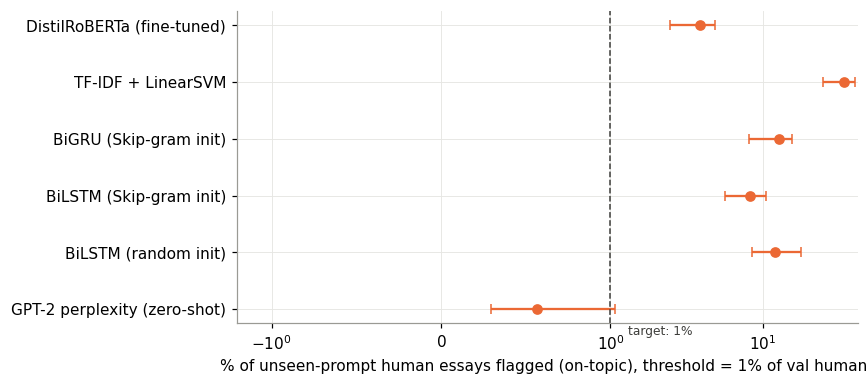

In [12]:
# one picture of the headline: held-out-prompt false flags, point and full-pipeline interval, per model
d = comparison[(comparison['subset'] == 'on-topic only') & (comparison['metric'] == 'humans flagged: held-out prompts')].set_index('model').loc[list(MODELS)[::-1]]
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(d))
ax.errorbar(d['point'], y, xerr=[d['point'] - d['boot_lo'], d['boot_hi'] - d['point']], fmt='o', color=AI, ecolor=AI, capsize=3)
ax.set_yticks(y); ax.set_yticklabels(d.index)
ax.axvline(1, color='#3d3d3a', linestyle='--', linewidth=1)
ax.text(1.3, -0.45, 'target: 1%', fontsize=8, color='#3d3d3a')
ax.set_xlabel('% of unseen-prompt human essays flagged (on-topic), threshold = 1% of val humans')
ax.set_xscale('symlog', linthresh=1)
fig.tight_layout(); fig.savefig('../images/15_heldout_false_flags.png', dpi=150, bbox_inches='tight'); plt.show()

## 5 · Do the README and model-card claims survive their error bars?

Each headline claim is re-computed with its interval from the per-essay scores (or from the saved per-essay CSVs of notebooks 13 and 14, or the counts they imply). The question for each is "is the difference the claim relies on larger than the noise?", not "is the number right". A claim *holds* if its interval excludes what it is being compared with; it is *not supported* if the intervals overlap or the sample is too small. Numbers that rest on results with no per-essay scores saved (averaged GloVe, length-only, the frozen DistilRoBERTa) cannot be checked and are listed as such.

In [13]:
rows = []
def claim(text, where, k=None, n=None, value=None, lo=None, hi=None, note=''):
    if k is not None:
        value = 100 * k / n; l, h = wilson_interval(k, n); lo, hi = 100 * l, 100 * h
    rows.append({'claim': text, 'where': where, 'k': k, 'n': n, 'value %': value, 'lo': lo, 'hi': hi, 'note': note})

on = ev[ev['on_topic']]
def flagged(d, col, thr): return int((scores.loc[d.index, col] >= thr).sum()), len(d)
thr_strict = threshold_for_fpr(val_arr['DistilRoBERTa (fine-tuned)'], 0.005)
thr_std = thr0['DistilRoBERTa (fine-tuned)']
h_test = on[(on['split'] == 'test') & (on['label'] == 0)]
h_ho = on[(on['split'] == 'heldout_prompt') & (on['label'] == 0)]
h_sum = h_ho[h_ho['prompt_name'] == 'Summer projects']; h_elec = h_ho[h_ho['prompt_name'] != 'Summer projects']
a_gen = on[(on['split'] == 'heldout_generator')]

# threshold-based rates for DistilRoBERTa
for name, d in [('test humans', h_test), ('unseen-prompt humans', h_ho), ('Summer projects humans', h_sum), ('Electoral college humans', h_elec)]:
    k, n = flagged(d, 'roberta', thr_strict); claim(f'{name} flagged, strict (0.5%) threshold', 'README, MODEL_CARD, 09', k, n)
for name, d in [('test humans', h_test), ('unseen-prompt humans', h_ho), ('Summer projects humans', h_sum), ('Electoral college humans', h_elec)]:
    k, n = flagged(d, 'roberta', thr_std); claim(f'{name} flagged, standard (1%) threshold', 'README, MODEL_CARD, 09, 14', k, n)
for tname, thr in [('strict', thr_strict), ('standard', thr_std)]:
    k, n = flagged(a_gen, 'roberta', thr)
    claim(f'unseen AI generators detected, {tname} threshold', 'README headline, MODEL_CARD', k, n)
k, n = flagged(a_gen, 'roberta', 0.0); claim('unseen AI generators detected, default threshold', 'README table (99.9%)', k, n)

# the "4-8x higher on unseen prompts" statement: ratio of two rates, bootstrap (threshold fixed at strict)
rng = np.random.default_rng(SEED)
sa, sb = ClusterSampler(h_test['dup_cluster']), ClusterSampler(h_ho['dup_cluster'])
xa, xb = (scores.loc[h_test.index, 'roberta'] >= thr_strict).to_numpy(), (scores.loc[h_ho.index, 'roberta'] >= thr_strict).to_numpy()
ratios = []
for _ in range(N_BOOT):
    ra, rb = xa[sa.draw(rng)].mean(), xb[sb.draw(rng)].mean()
    if ra > 0: ratios.append(rb / ra)
claim('false-flag rate is several times higher on unseen prompts (ratio, strict)', 'MODEL_CARD ("4-8x")', value=xb.mean() / xa.mean(),
      lo=np.percentile(ratios, 2.5), hi=np.percentile(ratios, 97.5), note='ratio, not %')
rng = np.random.default_rng(SEED)
ss, se = ClusterSampler(h_sum['dup_cluster']), ClusterSampler(h_elec['dup_cluster'])
xs, xe = (scores.loc[h_sum.index, 'roberta'] >= thr_std).to_numpy(), (scores.loc[h_elec.index, 'roberta'] >= thr_std).to_numpy()
diff = [xs[ss.draw(rng)].mean() - xe[se.draw(rng)].mean() for _ in range(N_BOOT)]
claim('Summer projects worse than Electoral college (difference in % flagged, standard)', 'MODEL_CARD ("7.7%")', value=100 * (xs.mean() - xe.mean()),
      lo=100 * np.percentile(diff, 2.5), hi=100 * np.percentile(diff, 97.5), note='percentage points')

# model comparisons on AUC, paired bootstrap (same resampled essays for both models)
def auc_diff(d, a, b):
    sampler = ClusterSampler(d['dup_cluster']); y = d['label'].to_numpy(); sa_, sb_ = scores.loc[d.index, a].to_numpy(), scores.loc[d.index, b].to_numpy()
    rng = np.random.default_rng(SEED); out = []
    for _ in range(N_BOOT):
        r = sampler.draw(rng)
        if 0 < y[r].sum() < len(r): out.append(roc_auc_score(y[r], sa_[r]) - roc_auc_score(y[r], sb_[r]))
    return roc_auc_score(y, sa_) - roc_auc_score(y, sb_), *np.percentile(out, [2.5, 97.5])
ho_on = on[on['split'] == 'heldout_prompt']
v, lo, hi = auc_diff(ho_on, 'roberta', 'tfidf'); claim('DistilRoBERTa beats TF-IDF on unseen-prompt AUC (difference)', 'README table (1.000 vs 0.997)', value=v, lo=lo, hi=hi, note='AUC difference')
v, lo, hi = auc_diff(ho_on, 'bilstm_sg', 'bilstm_rand'); claim('Skip-gram init vs random init, unseen-prompt AUC (difference)', 'README / 07 ("no head start")', value=v, lo=lo, hi=hi, note='AUC difference')
v, lo, hi = auc_diff(ho_on, 'bigru_sg', 'bilstm_sg'); claim('BiGRU vs BiLSTM, unseen-prompt AUC (difference)', '07', value=v, lo=lo, hi=hi, note='AUC difference')

# detection of unseen generators at each model's DEFAULT threshold (07 / 04 ordering BiGRU > BiLSTM > TF-IDF)
for col, name in [('bigru_sg', 'BiGRU'), ('bilstm_sg', 'BiLSTM'), ('tfidf', 'TF-IDF + SVM')]:
    k, n = flagged(a_gen, col, 0.0); claim(f'{name}: unseen generators detected, default threshold', 'README table / 07', k, n)
k, n = flagged(a_gen, 'gpt2', thr0['GPT-2 perplexity (zero-shot)']); claim('GPT-2 perplexity: unseen generators detected (val 1% threshold)', 'README ("17.8%")', k, n)
for tname, thr in [('default (0)', 0.0), ('val 1%', thr0['TF-IDF + LinearSVM'])]:
    k, n = flagged(h_ho, 'tfidf', thr); claim(f'TF-IDF: unseen-prompt humans flagged at {tname}', 'MODEL_CARD / 09 ("2.1% -> 33.8%")', k, n)

# attack results (13): counts implied by the saved percentages (n = 473 test AI, 300 humans)
for label, pct, n in [('AI caught, no attack (test)', 99.58, 473), ('AI caught, typos 10% (test)', 98.94, 473), ('AI caught, T5 light (test)', 99.58, 473),
                      ('AI caught, T5 heavy (test)', 96.41, 473), ('humans flagged, no attack', 0.67, 300), ('humans flagged, after T5 light paraphrase', 2.67, 300),
                      ('humans flagged, after T5 heavy paraphrase', 0.33, 300)]:
    claim(label, '13 / README / MODEL_CARD', round(pct * n / 100), n)

# 14: false positives are longer / have fewer misspellings; the splice test
err = pd.read_csv('../results/14_errors.csv'); fh = err[(err['label'] == 0)]
fp, ok = fh[fh['flagged']], fh[~fh['flagged']]
rng = np.random.default_rng(SEED)
for col, fn, label in [('n_words', np.median, 'median words, flagged humans minus other humans'), ('misspell_pct', np.mean, 'misspelling % of words, flagged minus other humans')]:
    a, b = fp[col].to_numpy(), ok[col].to_numpy(); d = []
    for _ in range(N_BOOT): d.append(fn(rng.choice(a, len(a))) - fn(rng.choice(b, len(b))))
    claim(label, 'MODEL_CARD / 14 (489 vs 441 words; 0.00% vs 0.56%)', value=fn(a) - fn(b), lo=np.percentile(d, 2.5), hi=np.percentile(d, 97.5),
          note=f'{len(fp)} flagged vs {len(ok)} other humans; difference')
sp = pd.read_csv('../results/14_splice_test.csv'); claim('partly-AI essays (3 AI sentences inserted) flagged', 'MODEL_CARD ("3%")', int(sp['flagged'].sum()), len(sp))
d = []
for _ in range(N_BOOT):
    i = rng.integers(0, len(sp), len(sp)); d.append(sp['p@3 integrated gradients'].to_numpy()[i].mean() - sp['p@3 random'].to_numpy()[i].mean())
claim('IG precision@3 minus random precision@3 on spliced essays', '14 (14.5% vs 22.8%)', value=100 * (sp['p@3 integrated gradients'].mean() - sp['p@3 random'].mean()),
      lo=100 * np.percentile(d, 2.5), hi=100 * np.percentile(d, 97.5), note=f'n={len(sp)} essays; percentage points')

# 11: attribution on unseen sources
loso = pd.read_csv('../results/11_attribution_loso.csv')
loso['k'] = (loso['% correct family'] * loso['essays'] / 100).round().astype(int)
for _, r in loso.iterrows():
    lo_, hi_ = wilson_interval(int(r['k']), int(r['essays']))
    rows.append({'claim': f"attribution of unseen source {r['held-out source']} ({r['model']}) correct family", 'where': 'README / MODEL_CARD ("0-28%")', 'k': int(r['k']),
                 'n': int(r['essays']), 'value %': r['% correct family'], 'lo': 100 * lo_, 'hi': 100 * hi_, 'note': ''})

audit = pd.DataFrame(rows)
audit.round(5).to_csv('../results/15_claims_audit.csv', index=False)
audit[~audit['claim'].str.startswith('attribution')].round(4).drop(columns=['where']).to_string(index=False)

'                                                                           claim      k      n  value %       lo       hi                                         note\n                                    test humans flagged, strict (0.5%) threshold    9.0 2272.0   0.3961   0.2085   0.7512                                             \n                           unseen-prompt humans flagged, strict (0.5%) threshold  102.0 4420.0   2.3077   1.9047   2.7935                                             \n                         Summer projects humans flagged, strict (0.5%) threshold   90.0 1746.0   5.1546   4.2124   6.2938                                             \n                       Electoral college humans flagged, strict (0.5%) threshold   12.0 2674.0   0.4488   0.2569   0.7828                                             \n                                    test humans flagged, standard (1%) threshold   21.0 2272.0   0.9243   0.6053   1.4089                                      

In [14]:
a = audit[audit['claim'].str.startswith('attribution')]
print(f"attribution on unseen sources: {len(a)} source/model rows, observed {a['value %'].min():.1f}%-{a['value %'].max():.1f}% correct; "
      f"upper Wilson limits {a['hi'].min():.1f}%-{a['hi'].max():.1f}% (chance for 8 families = 12.5%)")
a.round(1).drop(columns=['where', 'note']).to_string(index=False)

attribution on unseen sources: 8 source/model rows, observed 0.0%-28.1% correct; upper Wilson limits 0.8%-33.0% (chance for 8 families = 12.5%)


'                                                                                              claim    k     n  value %   lo   hi\n                         attribution of unseen source radek_500 (TF-IDF + LinearSVM) correct family  0.0 500.0      0.0  0.0  0.8\n                              attribution of unseen source radek_500 (DistilRoBERTa) correct family  0.0 500.0      0.0  0.0  0.8\n                  attribution of unseen source palm-text-bison1 (TF-IDF + LinearSVM) correct family 98.0 349.0     28.1 23.6 33.0\n                       attribution of unseen source palm-text-bison1 (DistilRoBERTa) correct family 86.0 349.0     24.6 20.4 29.4\n   attribution of unseen source NousResearch/Llama-2-7b-chat-hf (TF-IDF + LinearSVM) correct family 70.0 400.0     17.5 14.1 21.5\n        attribution of unseen source NousResearch/Llama-2-7b-chat-hf (DistilRoBERTa) correct family  1.0 400.0      0.2  0.0  1.4\nattribution of unseen source mistralai/Mistral-7B-Instruct-v0.1 (TF-IDF + LinearSV

### A confound in "the wrongly flagged essays are longer"

135 of the 191 false flags in notebook 14 come from one prompt, "Summer projects", whose human essays are long anyway (median 586 words, the longest of any prompt). Comparing flagged humans with *all other* humans therefore mixes a topic effect with whatever the model does. The fair comparison is **within the same prompt**.

In [15]:
e = pd.read_csv('../results/14_errors.csv')
h = e[(e['label'] == 0) & (e['prompt_name'] == 'Summer projects')]
fp_s, ok_s = h[h['flagged']], h[~h['flagged']]
rng = np.random.default_rng(SEED)
out = []
for col, fn, name in [('n_words', np.median, 'median words'), ('n_words', np.mean, 'mean words'), ('misspell_pct', np.mean, 'mean misspelling % of words')]:
    a, b = fp_s[col].to_numpy(), ok_s[col].to_numpy()
    d = [fn(rng.choice(a, len(a))) - fn(rng.choice(b, len(b))) for _ in range(N_BOOT)]
    out.append({'within Summer projects': name, 'flagged': fn(a), 'not flagged': fn(b), 'difference': fn(a) - fn(b),
                'lo': np.percentile(d, 2.5), 'hi': np.percentile(d, 97.5)})
print(f'{len(fp_s)} flagged vs {len(ok_s)} not flagged, all Summer projects humans')
pd.DataFrame(out).round(3)

135 flagged vs 1611 not flagged, all Summer projects humans


,within Summer projects,flagged,not flagged,difference,lo,hi
0,median words,597.000,586.000,11.000,-54.025,67.000
1,mean words,599.881,607.021,-7.140,-48.415,30.172
2,mean misspelling % of words,0.155,0.304,-0.149,-0.213,-0.078


In [16]:
# the AUC differences, with enough digits to read (the audit table above rounds them)
for _, r in audit[audit['note'] == 'AUC difference'].iterrows():
    print(f"{r['claim']:70s} {r['value %']:+.4f}  [{r['lo']:+.4f}, {r['hi']:+.4f}]")
a = audit[audit['claim'].str.startswith('attribution')]
print('\nattribution rows whose whole interval is ABOVE chance (12.5%):')
print(a[a['lo'] > 12.5][['claim', 'k', 'n', 'value %', 'lo', 'hi']].round(1).to_string(index=False))

DistilRoBERTa beats TF-IDF on unseen-prompt AUC (difference)           +0.0026  [+0.0019, +0.0034]
Skip-gram init vs random init, unseen-prompt AUC (difference)          -0.0038  [-0.0080, +0.0006]
BiGRU vs BiLSTM, unseen-prompt AUC (difference)                        -0.0195  [-0.0229, -0.0164]

attribution rows whose whole interval is ABOVE chance (12.5%):
                                                                                           claim    k     n  value %   lo   hi
               attribution of unseen source palm-text-bison1 (TF-IDF + LinearSVM) correct family 98.0 349.0     28.1 23.6 33.0
                    attribution of unseen source palm-text-bison1 (DistilRoBERTa) correct family 86.0 349.0     24.6 20.4 29.4
attribution of unseen source NousResearch/Llama-2-7b-chat-hf (TF-IDF + LinearSVM) correct family 70.0 400.0     17.5 14.1 21.5


### Verdict on each claim

**Holds up (the interval excludes what it is compared with)**

| Claim | Evidence |
|---|---|
| False flags are several times higher on unseen prompts than on familiar ones | ratio 5.8× at the strict threshold, 95% interval **3.3 to 15.6**. The model card's "4–8×" is a fair midpoint but the honest statement is "roughly 3 to 16 times". |
| Summer projects is much worse than Electoral college | 7.7% vs 1.3% at the standard threshold; difference **+6.4 points [5.0, 7.8]**. A real topic effect, not noise. |
| Unseen AI generators are caught about 99% of the time | strict 99.2% [98.7, 99.5], standard 99.8% [99.4, 99.9] |
| TF-IDF's threshold collapses on new topics | unseen-prompt humans flagged 2.1% at its default threshold but **33.8% [32.4, 35.2]** at the val-1% threshold |
| DistilRoBERTa ranks unseen prompts better than TF-IDF | AUC difference +0.0026 [+0.0019, +0.0034]. Real, but tiny: the practical gap is in the *threshold* (3.9% vs 33.8% false flags at val-1%), not in AUC. |
| BiGRU > BiLSTM > TF-IDF on unseen-generator detection at default thresholds | 95.6% [94.6, 96.4], 90.8% [89.5, 92.0], 88.0% [86.5, 89.3]: non-overlapping. **But among these three the order changes at the val-1% threshold** (TF-IDF 99.4%, BiGRU 96.5%, BiLSTM 92.0%): the ranking belongs to the threshold, not to the models. DistilRoBERTa, the best of all, is at 99.8% there. |
| Heavy T5 paraphrase lowers detection | 99.6% [98.5, 99.9] to 96.4% [94.3, 97.7] on 473 essays |
| Integrated gradients is blind on human-looking essays | precision@3 is **below** random: −8.3 points [−10.8, −5.4] |
| GPT-2 perplexity finds few unseen generators | 17.8% [16.2, 19.5] |
| **Added after Phase 2:** inside a prompt, long human essays are flagged *less* than short ones (corrects notebook 14 and the model card's "the wrongly flagged essays are longer") | within Electoral college 0.8% vs 1.7%, within Summer projects 6.9% vs 10.5% (first-512, val-1% threshold); prompt-adjusted pooled difference in the addendum below. The pooled rise of false flags with length is topic composition (77% of Summer projects essays are long). From `16_long_essays.ipynb`. |

**Not supported, or weaker than written**

| Claim | Problem |
|---|---|
| "Paraphrasing human essays with T5 raised their flag rate from 0.7% to 2.7%" (README, model card) | 2/300 [0.2, 2.4] vs 8/300 [1.4, 5.2]: the intervals overlap, and the heavy paraphrase gives 1/300. A suggestive trend from 6 extra essays, not a finding. |
| "Typos in 10% of words: 98.9% still caught" as a drop from 99.6% | 471/473 [98.5, 99.9] vs 468/473 [97.6, 99.6]: no detectable drop. "Still caught" is fine; any decline is not shown. |
| "The wrongly flagged essays are longer (median 489 vs 441 words)" | the median difference is **+48 [−12, +131]**: not significant. The mean difference (+70 words) is, but 135 of the 191 false flags are Summer projects, a long-essay prompt. Within Summer projects the lengths are close (see the table above). Mostly a topic effect. |
| "Attribution is at or below chance (12.5%) for held-out sources" | observed 0–28%, but with 349–500 essays per source some rows are significantly *above* 12.5% (listed above). "Unreliable and often wrong" is supported; "at or below chance" is not, for all sources. |
| The headline "2.3% of unseen-prompt humans flagged (target 0.5%)" as a single number | 2.31% [1.9, 2.8] if the threshold were fixed, but the threshold itself moves: with a different validation draw it would have been 5.4 to 9.1 logits, and the rate **0.9% to 3.6%**. It should be quoted with that range. |
| "The strict threshold is chosen for a 0.5% target" | it rests on **12 validation humans** (2,291 × 0.5%). The 1% threshold rests on 23. |
| "One essay dropped below the threshold with 5% typos" (model card) | n = 1; anecdote, not evidence. Phase 5 will test it properly. |

| **Added after Phase 2b:** flagged students write more predictable, formulaic text than other students of the same prompt | within-prompt, GPT-2 log-perplexity −0.95 SD, misspellings −0.43 SD, AI-typical vocabulary +0.54 SD (intervals in section 7); length is not higher. |

**Not supported (added after Phase 2b):** "a flagged essay stays flagged" — on the median fold only 28 of the 72 humans flagged by at least one seed are flagged by all three (39%, section 7).

**Cannot be checked from saved results** (no per-essay scores were kept): averaged GloVe / Word2Vec AUCs, the length-only and prompt-only references, the frozen-encoder DistilRoBERTa, and the notebook-13 paired comparisons. They stay as point estimates.

## 6 · Addendum after Phase 2: is "longer essays are flagged more" true inside a prompt?

`16_long_essays.ipynb` found that, within one prompt, long essays (more than 510 tokens, the ones the model cuts off) are flagged **less** than short ones. Here that is added to the claims audit with intervals, in three rows: Electoral college, Summer projects, and a **prompt-adjusted** difference over all 15 prompts of `test` + held-out prompts (for each prompt: flagged share among long minus among short, averaged with weights proportional to the prompt's number of humans, so the topic mix cancels out). Intervals are cluster bootstraps of the humans, with the standard (1%) threshold fixed. Rates use the first-512 DistilRoBERTa scores, exactly as in the claims above.

In [17]:
win = pd.read_csv('../results/16_window_scores.csv', index_col='row_id')
hh = ev[(ev['label'] == 0) & ev['split'].isin(['test', 'heldout_prompt'])].copy()
hh['n_tokens'] = win.loc[hh.index, 'n_tokens']
hh['long'] = (hh['n_tokens'] > 510).to_numpy()
hh['flag'] = (scores.loc[hh.index, 'roberta'] >= thr_std).to_numpy()

def diff_long_short(frame, prompts_adjusted=False):
    """(point, lo, hi) in percentage points of rate(long) - rate(short); prompt-adjusted if asked."""
    code = pd.factorize(frame['prompt_name'])[0] if prompts_adjusted else np.zeros(len(frame), dtype=int)
    L, F = frame['long'].to_numpy().astype(int), frame['flag'].to_numpy().astype(int)
    n_p = code.max() + 1
    def stat(rows):
        cell = code[rows] * 2 + L[rows]
        n = np.bincount(cell, minlength=2 * n_p).reshape(n_p, 2)
        k = np.bincount(cell, weights=F[rows], minlength=2 * n_p).reshape(n_p, 2)
        ok = (n > 0).all(axis=1)
        if not ok.any(): return np.nan
        w = n[ok].sum(axis=1)
        return 100 * float((w * (k[ok, 1] / n[ok, 1] - k[ok, 0] / n[ok, 0])).sum() / w.sum())
    return bootstrap_interval(stat, len(frame), groups=frame['dup_cluster'].to_numpy(), n_boot=N_BOOT)

new = []
for name, frame, adjusted in [('Electoral college', hh[hh['prompt_name'] == 'Does the electoral college work?'], False),
                              ('Summer projects', hh[hh['prompt_name'] == 'Summer projects'], False),
                              ('all 15 prompts, prompt-adjusted', hh, True)]:
    v, lo, hi = diff_long_short(frame, adjusted)
    ks = frame.groupby('long')['flag'].agg(['sum', 'size'])
    note = f"long {int(ks.loc[True, 'sum'])}/{int(ks.loc[True, 'size'])} vs short {int(ks.loc[False, 'sum'])}/{int(ks.loc[False, 'size'])}; percentage points, long minus short"
    new.append({'claim': f'false flags are higher for long human essays than short ones: {name} (standard threshold)',
                'where': 'MODEL_CARD / 14 ("the wrongly flagged essays are longer"); 16', 'k': np.nan, 'n': len(frame),
                'value %': v, 'lo': lo, 'hi': hi, 'note': note})
audit = pd.concat([audit, pd.DataFrame(new)], ignore_index=True)
audit.round(5).to_csv('../results/15_claims_audit.csv', index=False)
pd.DataFrame(new)[['claim', 'value %', 'lo', 'hi', 'note']].round(2).to_string(index=False)

'                                                                                                             claim  value %    lo    hi                                                                note\n              false flags are higher for long human essays than short ones: Electoral college (standard threshold)    -0.90 -1.92  0.05  long 10/1243 vs short 25/1471; percentage points, long minus short\n                false flags are higher for long human essays than short ones: Summer projects (standard threshold)    -3.65 -6.90 -0.57   long 92/1341 vs short 43/409; percentage points, long minus short\nfalse flags are higher for long human essays than short ones: all 15 prompts, prompt-adjusted (standard threshold)    -1.62 -2.57 -0.66 long 107/3439 vs short 84/3316; percentage points, long minus short'

## 7 · Addendum after Phase 2b: verdict stability across seeds, and what separates false flags

From `16b_topic_lopo.ipynb` (leave-one-prompt-out; per-essay scores in `results/16b_lopo/`, per-human features in `results/16b_lopo_human_essays.csv`). Two claims for the final documents:

1. **Individual verdicts are unstable across training seeds**, even though the overall false-flag rate is stable: on the median fold, of the human essays flagged by at least one of three seeds, how many were flagged by all three? (Wilson interval on that share.)
2. **Flagged students write more predictable, formulaic text than other students of the same prompt.** Within each of the 13 left-out prompts, each feature is standardised, and the flagged-minus-other difference (in SD units) gets a cluster-bootstrap interval, as in 16b.

In [18]:
l16 = pd.read_csv('../results/16b_lopo/log.csv')
seed_fold = int(l16[l16['seed'] != 42]['fold'].iloc[0])
seed_flags = {}
for sd in sorted(l16[l16['fold'] == seed_fold]['seed'].unique()):
    s16 = pd.read_csv(f'../results/16b_lopo/scores_fold{seed_fold:02d}_seed{sd}.csv', index_col='row_id')
    vh16 = s16[(s16['role'] == 'other_val') & (s16['label'] == 0)]['logit']
    left16 = s16[(s16['role'] == 'left_out') & (s16['label'] == 0)]
    seed_flags[sd] = left16['logit'] >= threshold_for_fpr(vh16, 0.01)
sf = pd.DataFrame(seed_flags)
ever, allthree = int((sf.sum(axis=1) > 0).sum()), int((sf.sum(axis=1) == sf.shape[1]).sum())
new = []
lo_, hi_ = wilson_interval(allthree, ever)
new.append({'claim': 'a flagged human essay is flagged again by every training seed (share of essays flagged by at least one of 3 seeds that all 3 flag; median fold, 1% threshold)',
            'where': '16b / Phase 2b', 'k': allthree, 'n': ever, 'value %': 100 * allthree / ever, 'lo': 100 * lo_, 'hi': 100 * hi_,
            'note': 'the false-flag RATE is stable across seeds (1.89-2.54%) but the SET of flagged essays is not'})

he = pd.read_csv('../results/16b_lopo_human_essays.csv', index_col='row_id').join(data[['dup_cluster']])
FEATS = {'log_ppl': 'GPT-2 log-perplexity (lower = more predictable)', 'misspell_pct': 'misspelling % of words', 'ai_vocab_pct': 'share of AI-typical vocabulary', 'n_words': 'length in words'}
for f, label in FEATS.items():
    z = he.groupby('prompt_name')[f].transform(lambda x: (x - x.mean()) / x.std()).to_numpy()
    fl = he['flag_0.01'].to_numpy().astype(bool)
    stat = lambda r, z=z, fl=fl: float(z[r][fl[r]].mean() - z[r][~fl[r]].mean()) if fl[r].any() else np.nan
    v, lo, hi = bootstrap_interval(stat, len(he), groups=he['dup_cluster'].to_numpy(), n_boot=N_BOOT)
    new.append({'claim': f'flagged humans differ from other humans of the same prompt: {label}', 'where': '16b / Phase 2b (corrects 14: longer essays)', 'k': np.nan, 'n': len(he),
                'value %': v, 'lo': lo, 'hi': hi, 'note': f"SD units within prompt, flagged minus other; {int(he['flag_0.01'].sum())} flagged of {len(he):,} humans, 13 left-out prompts"})
audit = pd.concat([audit, pd.DataFrame(new)], ignore_index=True)
audit.round(5).to_csv('../results/15_claims_audit.csv', index=False)
pd.DataFrame(new)[['claim', 'value %', 'lo', 'hi']].round(2).to_string(index=False)

'                                                                                                                                                        claim  value %    lo    hi\na flagged human essay is flagged again by every training seed (share of essays flagged by at least one of 3 seeds that all 3 flag; median fold, 1% threshold)    38.89 28.47 50.44\n                                                  flagged humans differ from other humans of the same prompt: GPT-2 log-perplexity (lower = more predictable)    -0.95 -1.01 -0.88\n                                                                           flagged humans differ from other humans of the same prompt: misspelling % of words    -0.43 -0.48 -0.37\n                                                                   flagged humans differ from other humans of the same prompt: share of AI-typical vocabulary     0.54  0.43  0.65\n                                                                                  flagged humans di

## 8 · Addendum after Phase 3: the training variants, thresholds that do not transfer, and what was not tested

From `17_augment.ipynb` / `17b_augment_results.ipynb` (seven pre-registered leave-one-prompt-out folds, seed 42; three final models of variant A). Rows added to the claims audit:

1. **The three variants against the original recipe** (primary statistic, paired bootstrap, as pre-registered). Variant C's better worst-prompt rate and Exploring Venus result are **exploratory only**: the interval for C minus A on the worst prompt is shown and it spans zero.
2. **A 1% threshold belongs to one trained model.** The val-chosen 1% logit thresholds of the three final models of variant A (same recipe, seeds 42, 43, 44), with a cluster-bootstrap interval each and the validation AUC.
3. **The spelling corrector is wrong on about one correction in six.** Hand-read sample of 60 random corrections (single reader, the list in `17_augment.ipynb`): 10 judged wrong (e.g. "emmisions" → "emmissions", "compeling" → "competing", "probly" → "proby").
4. **Not tested:** the repair-versus-injection ablation (which half of augmentation A matters).

In [19]:
from src.compare import analyse
lp = pd.read_csv('../results/10_gpt2_features.csv', index_col='row_id')['log_ppl']
FOLDS7 = [11, 4, 3, 6, 7, 12, 2]
new = []
for v, what in [('A', 'spelling/typo augmentation'), ('B', 'predictability-matched weights'), ('C', 'A + B')]:
    per_v, o = analyse(v, FOLDS7, data, lp)
    p = o['primary']
    new.append({'claim': f'variant {v} ({what}) lowers the false-flag rate on unseen topics (mean over 7 prompts, 1% threshold, vs original recipe)',
                'where': '17b / Phase 3', 'k': np.nan, 'n': 7, 'value %': p[0], 'lo': p[1], 'hi': p[2],
                'note': f"percentage points, paired bootstrap incl. threshold noise; guardrail val AI caught {o['guardrail'][0]:+.2f} pts; wins={o['wins']}; one seed per fold"})
per_ca, o_ca = analyse('C', FOLDS7, data, lp, base_dir='../results/17_variants/A')
w = o_ca['worst']
new.append({'claim': 'variant C has a better worst-prompt false-flag rate than variant A (EXPLORATORY, not part of the pre-registered rule)', 'where': '17b / Phase 3',
            'k': np.nan, 'n': 7, 'value %': w[2], 'lo': w[3], 'hi': w[4],
            'note': f'worst prompt: A {w[0]:.2f}% -> C {w[1]:.2f}% (percentage points, C minus A); the interval spans zero, so not supported; C minus A on the primary statistic {o_ca["primary"][0]:+.2f} [{o_ca["primary"][1]:+.2f}, {o_ca["primary"][2]:+.2f}]'})

fl = pd.read_csv('../results/17_final/log.csv'); fl = fl[fl['variant'] == 'A'].set_index('seed')
vh_all = data[(data['split'] == 'val') & (data['label'] == 0)]
for sd in (42, 43, 44):
    s17 = pd.read_csv(f'../results/17_final/aug_s{sd}_scores.csv', index_col='row_id')
    vv = s17[(s17['role'] == 'val') & (s17['label'] == 0)]['logit']
    smp = ClusterSampler(data.loc[vv.index, 'dup_cluster']); arr_v = vv.to_numpy(); rng_t = np.random.default_rng(SEED)
    d_thr = [np.quantile(arr_v[smp.draw(rng_t)], 0.99) for _ in range(N_BOOT)]
    thr = float(np.quantile(arr_v, 0.99))
    new.append({'claim': f'the val-chosen 1% logit threshold of a trained model carries over to another seed of the same recipe (variant A, seed {sd})',
                'where': '17b / Phase 3 (NOT supported)', 'k': np.nan, 'n': len(vv), 'value %': thr, 'lo': float(np.percentile(d_thr, 2.5)), 'hi': float(np.percentile(d_thr, 97.5)),
                'note': f"logits, not percent; val AUC {fl.loc[sd, 'val_auc']:.5f}; the three seeds' thresholds are +4.57, +3.58 and -0.13 at near-identical AUC, so a threshold belongs to ONE trained model"})
new.append({'claim': "the spell-checker's repairs are correct (hand-read sample of 60 random corrections, single reader)", 'where': '17_augment.ipynb / Phase 3 limitation',
            'k': 50, 'n': 60, 'value %': 100 * 50 / 60, 'lo': 100 * wilson_interval(50, 60)[0], 'hi': 100 * wilson_interval(50, 60)[1],
            'note': '10 of 60 judged wrong (about one in six); a limitation of variant A: the repaired essays contain some wrong words'})
new.append({'claim': 'the gain of variant A comes from repairing human spelling AND/OR from injecting typos in AI essays (which half matters)', 'where': '17b / Phase 3',
            'k': np.nan, 'n': np.nan, 'value %': np.nan, 'lo': np.nan, 'hi': np.nan, 'note': 'NOT TESTED: no ablation was run (optional later); the mechanism is plausible, not shown'})
audit = pd.concat([audit, pd.DataFrame(new)], ignore_index=True)
audit.round(5).to_csv('../results/15_claims_audit.csv', index=False)
pd.DataFrame(new)[['claim', 'value %', 'lo', 'hi']].round(2).to_string(index=False)

"                                                                                                                                         claim  value %    lo    hi\n    variant A (spelling/typo augmentation) lowers the false-flag rate on unseen topics (mean over 7 prompts, 1% threshold, vs original recipe)    -0.86 -1.50 -0.26\nvariant B (predictability-matched weights) lowers the false-flag rate on unseen topics (mean over 7 prompts, 1% threshold, vs original recipe)    -0.17 -0.61  0.33\n                         variant C (A + B) lowers the false-flag rate on unseen topics (mean over 7 prompts, 1% threshold, vs original recipe)    -0.80 -1.58 -0.38\n                         variant C has a better worst-prompt false-flag rate than variant A (EXPLORATORY, not part of the pre-registered rule)    -0.77 -3.11  0.91\n                     the val-chosen 1% logit threshold of a trained model carries over to another seed of the same recipe (variant A, seed 42)     4.57 -0.41  6.80\n         

## 9 · Addendum after Phase 4: the threshold rules, and variant A on all 13 folds

Rows added to the claims audit from `18_robust_threshold.ipynb` (read from `results/18_rule_comparison.csv`; leave-one-topic-out over the 13 leave-one-prompt-out score sets of variant A) and from the after-the-fact 13-fold extension of Phase 3 (`17b_augment_results.ipynb`, section 4).

In [20]:
cmp18 = pd.read_csv('../results/18_rule_comparison.csv')
r18 = {(r['rule'], r['target']): r for _, r in cmp18.iterrows()}
new = []
ra = r18[('a', 0.01)]
new.append({'claim': 'a 1% threshold set on pooled validation essays keeps the false-flag rate near 1% on new topics (mean over 13 left-out topics, variant A)', 'where': '18 / Phase 4 (NOT supported)',
            'k': np.nan, 'n': 13, 'value %': ra['mean_fpr'], 'lo': ra['mean_fpr_lo'], 'hi': ra['mean_fpr_hi'],
            'note': f"rule (a); {ra['share_over_target']:.0f}% of topics over the 1% target [{ra['share_over_target_lo']:.0f}, {ra['share_over_target_hi']:.0f}]; worst topic {ra['worst_fpr']:.1f}%; AI caught {ra['mean_ai_caught']:.2f}%"})
rb = r18[('b', 0.01)]
new.append({'claim': 'a 1% threshold set on the pooled left-out-topic humans (rule b, the pre-declared choice) keeps the mean false-flag rate on new topics near 1% (13 left-out topics, variant A)', 'where': '18 / Phase 4',
            'k': np.nan, 'n': 13, 'value %': rb['mean_fpr'], 'lo': rb['mean_fpr_lo'], 'hi': rb['mean_fpr_hi'],
            'note': f"{rb['share_over_target']:.0f}% of topics still over the target [{rb['share_over_target_lo']:.0f}, {rb['share_over_target_hi']:.0f}]; worst topic {rb['worst_fpr']:.1f}%; AI caught {rb['mean_ai_caught']:.2f}% [{rb['mean_ai_caught_lo']:.2f}, {rb['mean_ai_caught_hi']:.2f}]"})
from src.compare import analyse as _an
lp2 = pd.read_csv('../results/10_gpt2_features.csv', index_col='row_id')['log_ppl']
for name, folds in (('all 13 prompts', list(range(13))), ('the 6 prompts added after Phase 3', [0, 1, 5, 8, 9, 10])):
    _, o13 = _an('A', folds, data, lp2)
    p13 = o13['primary']
    new.append({'claim': f'variant A lowers the false-flag rate on unseen topics vs the original recipe ({name}, 1% threshold)', 'where': '17b section 4 (after the fact; NOT supported)',
                'k': np.nan, 'n': len(folds), 'value %': p13[0], 'lo': p13[1], 'hi': p13[2],
                'note': f"percentage points, positive = A flags MORE humans; guardrail val AI caught {o13['guardrail'][0]:+.2f}; dominated by Cowboy (4.30% -> 17.42%); the 7 pre-registered folds were chosen from the extremes"})
audit = pd.concat([audit, pd.DataFrame(new)], ignore_index=True)
audit.round(5).to_csv('../results/15_claims_audit.csv', index=False)
pd.DataFrame(new)[['claim', 'value %', 'lo', 'hi']].round(2).to_string(index=False)

'                                                                                                                                                                        claim  value %   lo   hi\n                                     a 1% threshold set on pooled validation essays keeps the false-flag rate near 1% on new topics (mean over 13 left-out topics, variant A)     3.37 2.86 3.96\na 1% threshold set on the pooled left-out-topic humans (rule b, the pre-declared choice) keeps the mean false-flag rate on new topics near 1% (13 left-out topics, variant A)     1.58 1.09 1.79\n                                                                  variant A lowers the false-flag rate on unseen topics vs the original recipe (all 13 prompts, 1% threshold)     0.57 0.19 1.16\n                                               variant A lowers the false-flag rate on unseen topics vs the original recipe (the 6 prompts added after Phase 3, 1% threshold)     2.24 1.70 3.18'

## Key takeaways

- **Every number now has a range.** The per-essay scores of all six models are in `results/15_scores.csv`, and `src/evaluate.py` has the Wilson interval, a cluster bootstrap and the threshold helper. Later notebooks should use them.
- **The thresholds are noisy.** The strict threshold sits at logit 7.80 (95% range 5.43 to 9.05) and rests on 12 validation humans; the standard one at 4.67 (2.20 to 7.48) on 23. The implied unseen-prompt false-flag rate is 0.9–3.6% (strict) and 2.4–4.9% (standard).
- **Topic is the dominant error source, not the threshold.** Summer projects is flagged 5.2% (strict) / 7.7% (standard) against 0.45% / 1.3% for Electoral college. A better threshold rule cannot fix a 6-point topic gap on its own (Phase 4); the model must change (Phases 2, 3).
- **At the same 1% threshold DistilRoBERTa is the only model that is both accurate and calibrated on new topics** (unseen-prompt false flags 3.85% [2.5, 4.9] vs 8–34% for the others). GPT-2 flags only 0.6% of those humans, but also misses 82% of unseen-generator essays.
- **AUC cannot separate DistilRoBERTa from TF-IDF in practice** (0.9998 vs 0.9972). Report false flags and detection at a fixed threshold.
- **Corrected claims** are listed above; the docs are not edited yet. One finding to carry into Phase 3: the "longer essays" explanation of false flags is mostly a Summer-projects topic effect; the lower-misspelling signal is smaller within the prompt.
- **Added after Phase 2:** within a prompt, long essays are flagged less than short ones (section 6), so the pooled "longer essays are flagged more" pattern is topic composition.
- **Added after Phase 3:** a 1% threshold in logits belongs to one trained model (three seeds: +4.57, +3.58, −0.13 at near-identical AUC); the spell-checker is wrong on about one correction in six; variant C's better worst-prompt rate is exploratory only; the repair-vs-injection ablation was not run (section 8).
- **Added after Phase 4:** a 1% threshold on pooled val essays leaves 77% of new topics over target (mean 3.4%); the pooled leave-one-prompt-out rule (b) halves that (1.58%); variant A is not better than the original recipe on all 13 folds (+0.57 points [+0.19, +1.16]; section 9).